<!-- =========================
xaitoolkit — README.md
========================= -->

# **_Explain PyTorch vision models (CNNs) with practical XAI methods — gradient, perturbation, and surrogate-based._**
---

Author: Muhammad Rashid - University of Torino, Italy
<ul>
  <li> Python Package: https://pypi.org/project/xaitoolkit/
  <li> GitHub: https://github.com/rashidrao-pk/xaitoolkit
</ul>

## What this repo does

**_xaitoolkit_** is a lightweight toolkit to **explain the predictions of PyTorch image classifiers** (especially CNNs).  
It’s designed for researchers and engineers who want to plug in a **black-box model** (or a white-box PyTorch module) and quickly generate explanation heatmaps + overlays.

**Outputs saved per method**
<ul>
<li> outputs/original.png
<li> outputs/<method>_heatmap.png
<li> outputs/<method>_overlay.png
</ul>

## Quick start

In [1]:
%pip install -U xaitoolkit --quiet

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

In [3]:
import xaitoolkit

In [4]:
from xaitoolkit.xai_setup import xai_setup
model, preprocess, class_names, device, predict_proba, predict_topk = xai_setup("resnet50")
device

device(type='cuda')

## Load image

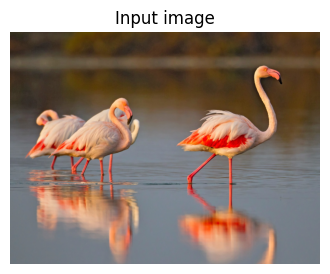

In [5]:
img_path = "../assets/flamingo.jpg"  # change if needed
pil = Image.open(img_path).convert("RGB")

plt.figure(figsize=(4,4))
plt.imshow(pil)
plt.axis("off")
plt.title("Input image")
plt.show()

## Preprocess + predict

In [6]:
x = preprocess(pil).unsqueeze(0).to(device)  # [1,3,224,224]
with torch.no_grad():
    logits = model(x)
    probs = torch.softmax(logits, dim=1)

pred_idx = int(probs.argmax(dim=1).item())
pred_prob = float(probs[0, pred_idx].item())
pred_name = class_names[pred_idx] if class_names is not None else str(pred_idx)

pred_idx, pred_prob, pred_name

(130, 0.5319652557373047, 'flamingo')

In [7]:
topk = 5
top_probs, top_idx = probs[0].topk(topk)
top_probs = top_probs.detach().cpu().numpy()
top_idx = top_idx.detach().cpu().numpy()
top_labels = [class_names[i] if class_names is not None else str(i) for i in top_idx]

for tp,ti,tl in zip(top_probs,top_idx,top_labels):
    print(f'{tl:<15} --> {tp:.5}')

flamingo        --> 0.53197
spoonbill       --> 0.0016156
chiffonier      --> 0.0013305
wardrobe        --> 0.0010864
redshank        --> 0.0010659


## Use xaitoolkit methods

In [8]:
from xaitoolkit.utils.viz import overlay_heatmap

# Create a resized image for overlay (match tensor spatial size)
H, W = x.shape[-2], x.shape[-1]
img01 = np.asarray(pil.resize((W, H))).astype(np.float32) / 255.0

## → Saliency (Vanilla Gradients)

**Purpose**  
Identify which input pixels most strongly influence the model’s prediction for a selected target class.

**How it works**  
This method computes how sensitive the model’s target class prediction is to small changes in each input pixel. It does so by backpropagating gradients from the target class output to the input image.

The magnitude of these gradients indicates how much changing a pixel would affect the model’s confidence. Gradients are typically aggregated across color channels (e.g., averaging over RGB) to produce a single 2D saliency heatmap.

**Interpretation**  
Pixels with higher saliency values correspond to regions where small input changes would have a strong effect on the target class score. These regions are considered more influential for the model’s decision.

**Strengths**
- Very fast (single forward and backward pass)  
- Simple and intuitive baseline for gradient-based explainability  
- Requires no additional hyperparameters  

**Limitations**
- Often noisy and highly sensitive to small input perturbations  
- May highlight edges or low-level textures rather than semantically meaningful regions  

**Reference**
- Simonyan et al., *Deep Inside Convolutional Networks: Visualising Image Classification Models and Saliency Maps*, 2013  
  https://arxiv.org/abs/1312.6034  
- Adebayo et al., *Sanity Checks for Saliency Maps*, NeurIPS 2018  
  https://arxiv.org/abs/1810.03292

**API usage**
```python
sal = explain_saliency(
    model=model,
    x=x,
    target_idx=pred_idx,
    device=device
)


In [9]:
%%time
from xaitoolkit.methods.saliency import explain_saliency
sal = explain_saliency(model=model, x=x, target_idx=pred_idx,device=device)
overlay_sal = overlay_heatmap(img01, sal)

CPU times: total: 391 ms
Wall time: 403 ms


## → SmoothGrad

**Purpose**  
Reduce the visual noise of vanilla saliency maps by averaging gradients over multiple slightly perturbed versions of the input image.

**How it works**  
Instead of computing gradients only once on the original input image, SmoothGrad repeatedly adds small random noise to the input and computes a saliency map for each noisy version. The final explanation is obtained by averaging these saliency maps.

The key intuition is that truly important features remain influential even when the input is slightly perturbed, while spurious gradient noise tends to cancel out during averaging.

**Interpretation**  
Image regions that consistently influence the target class prediction across multiple noisy samples receive higher importance. This produces smoother, more stable, and more visually coherent heatmaps compared to vanilla saliency.

**Strengths**
- Significantly reduces high-frequency noise in saliency maps  
- Highlights more coherent and interpretable regions  
- Simple extension of gradient-based attribution methods  

**Limitations**
- More computationally expensive due to multiple forward and backward passes  
- Sensitive to the choice of noise level and number of samples  
- Does not guarantee semantic correctness of explanations  

**Reference**
- Smilkov et al., *SmoothGrad: Removing Noise by Adding Noise*, 2017  
  https://arxiv.org/abs/1706.03825

**API usage**
```python
sg = explain_smoothgrad(
    model=model,
    x=x,
    target_idx=pred_idx,
    device=device,
    n_samples=30,
    noise_sigma=0.12
)


In [10]:
%%time
from xaitoolkit.methods.smoothgrad import explain_smoothgrad
sg  = explain_smoothgrad(model=model, x=x, target_idx=pred_idx,device=device, n_samples=30, noise_sigma=0.12)
overlay_sg  = overlay_heatmap(img01, sg)

CPU times: total: 891 ms
Wall time: 935 ms


## → Integrated Gradients (IG)

**Purpose**  
Integrated Gradients is a gradient-based explanation method designed to attribute a model’s prediction to its input features. It explains how much each pixel contributes to the final decision by comparing the model’s behavior on the input image against a chosen reference image, called the baseline.

**How it works**  
The method starts from a baseline input (for example, a completely black image or a blurred version of the input) and gradually transforms it into the actual input image. Along this transformation path, the model’s gradients with respect to the input are computed at multiple intermediate points. These gradients are then accumulated to estimate how each pixel influences the prediction as the image changes from the baseline to the original input.

In practice, this accumulation is performed using a fixed number of interpolation steps between the baseline and the input, making the method numerically tractable.

**Interpretation**  
A pixel receives a high attribution score if modifying it from the baseline value to its actual value consistently increases the confidence of the predicted class. Pixels with near-zero attribution have little influence on the model’s decision, while strongly positive or negative attributions indicate important evidence for or against the prediction.

**Strengths**
- More theoretically grounded than raw gradient methods  
- Satisfies important attribution principles such as sensitivity and completeness  
- Produces smoother and more stable explanations compared to vanilla saliency maps  

**Limitations**
- Requires selecting a suitable baseline, which can influence the explanation  
- Computationally more expensive than single-pass gradient methods  
- Operates at the pixel level and may not capture higher-level semantic concepts  

**Reference**
- Sundararajan et al., *Axiomatic Attribution for Deep Networks*, ICML 2017  
  https://arxiv.org/abs/1703.01365  

**API usage**
```python
ig = explain_ig(
    model=model,
    x=x,
    target_idx=pred_idx,
    device=device,
    steps=50,
    baseline=None  # defaults to a black image
)


In [11]:
%%time
from xaitoolkit.methods.ig import explain_ig
ig  = explain_ig(model=model, x=x, target_idx=pred_idx,device=device, steps=20)
overlay_ig  = overlay_heatmap(img01, ig)

CPU times: total: 188 ms
Wall time: 197 ms


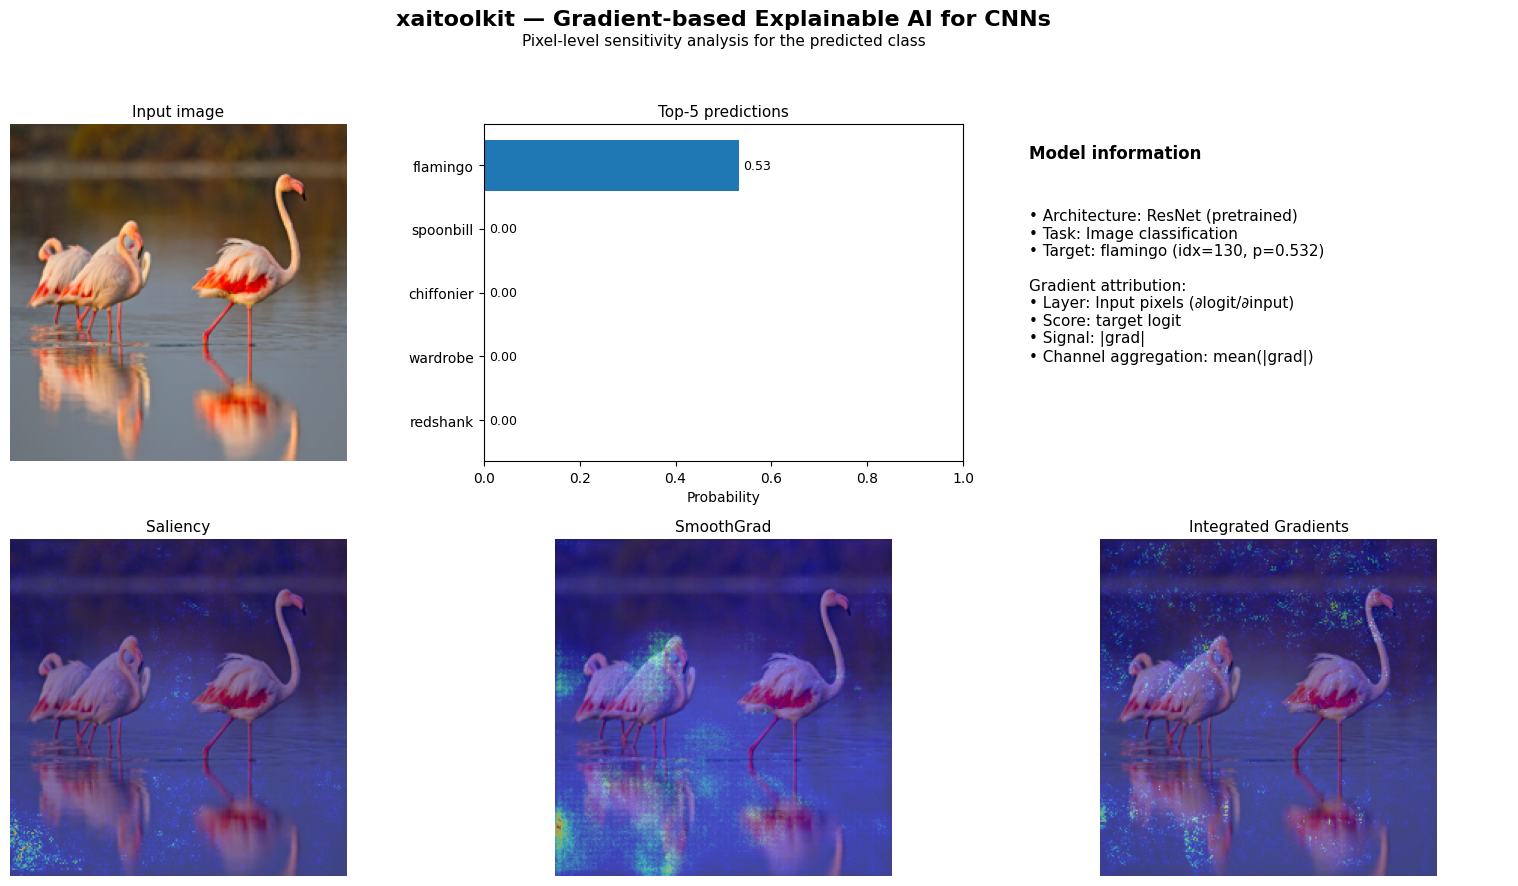

In [12]:
def _describe_model(model):
    return model.__class__.__name__

model_name = f"{_describe_model(model)} (pretrained)"

grad_layer = "Input pixels (∂logit/∂input)"
target_info = f"Target: {pred_name} (idx={pred_idx}, p={pred_prob:.3f})"

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

axes[0, 0].imshow(img01)
axes[0, 0].set_title("Input image", fontsize=11)
axes[0, 0].axis("off")

y_pos = np.arange(topk)
axes[0, 1].barh(y_pos, top_probs)
axes[0, 1].set_yticks(y_pos)
axes[0, 1].set_yticklabels(top_labels)
axes[0, 1].invert_yaxis()
axes[0, 1].set_xlim(0, 1.0)
axes[0, 1].set_xlabel("Probability")
axes[0, 1].set_title("Top-5 predictions", fontsize=11)
for i, p in enumerate(top_probs):
    axes[0, 1].text(p + 0.01, i, f"{p:.2f}", va="center", fontsize=9)

axes[0, 2].axis("off")
axes[0, 2].text(0.0, 0.9, "Model information", fontsize=12, fontweight="bold", transform=axes[0, 2].transAxes)
axes[0, 2].text(
    0.0, 0.75,
    f"• Architecture: {model_name}\n"
    f"• Task: Image classification\n"
    f"• {target_info}\n\n"
    f"Gradient attribution:\n"
    f"• Layer: {grad_layer}\n"
    f"• Score: target logit\n"
    f"• Signal: |grad|\n"
    f"• Channel aggregation: mean(|grad|)",
    fontsize=11,
    transform=axes[0, 2].transAxes,
    va="top"
)

axes[1, 0].imshow(overlay_sal); axes[1, 0].set_title("Saliency", fontsize=11); axes[1, 0].axis("off")
axes[1, 1].imshow(overlay_sg);  axes[1, 1].set_title("SmoothGrad", fontsize=11); axes[1, 1].axis("off")
axes[1, 2].imshow(overlay_ig);  axes[1, 2].set_title("Integrated Gradients", fontsize=11); axes[1, 2].axis("off")

fig.suptitle("xaitoolkit — Gradient-based Explainable AI for CNNs", fontsize=16, fontweight="bold", y=0.98)
fig.text(0.5, 0.94, "Pixel-level sensitivity analysis for the predicted class", ha="center", fontsize=11)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()


In [13]:
os.makedirs("outputs", exist_ok=True)
plt.imsave("outputs/saliency_overlay.png", overlay_sal)
plt.imsave("outputs/smoothgrad_overlay.png", overlay_sg)
plt.imsave("outputs/ig_overlay.png", overlay_ig)
print("Saved overlays to outputs/")

Saved overlays to outputs/
